# Ejercicio 8: los tres años juntos (2024, 2025 y 2026)

Con los Parquet de 2025 descargados y la tabla materializada completada con los 12 meses nuevos, aquí comparamos los tres años. Las consultas están en `sql/ejercicio_08/` y trabajan sobre la base `data/processed/taxis.duckdb` (en solo lectura) a través de las vistas `viajes_anio` y `viajes_limpios` del tablero. Como 2026 solo llega hasta agosto, las comparaciones por año usan enero a agosto de cada año, y cuando miramos mes a mes comparamos cada mes con el mismo mes del año anterior. La interpretación completa está en `docs/ejercicio_08.md`.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)

SQL = Path("/workspace/sql/ejercicio_08")
con = duckdb.connect("/workspace/data/processed/taxis.duckdb", read_only=True)
# Las medianas exactas sobre decenas de millones de filas necesitan memoria, y el
# contenedor comparte unos 5 GB con Metabase, asi que limitamos hilos y memoria.
con.execute("SET threads = 4")
con.execute("SET memory_limit = '2GB'")

def correr(nombre):
    """Muestra el SQL del archivo y devuelve su resultado."""
    texto = (SQL / f"{nombre}.sql").read_text(encoding="utf-8")
    print(texto)
    return con.sql(texto).df()

print(con.sql("SELECT anio_archivo AS anio, tipo, count(*) AS viajes FROM viajes GROUP BY ALL ORDER BY 1, 2").df().to_string(index=False))

 anio   tipo   viajes
 2024  green   660218
 2024 yellow 41169720
 2025  green   591375
 2025 yellow 48722602
 2026  green   337114
 2026 yellow 29703355


## 8.3 Las consultas anteriores siguen funcionando

Las consultas de los ejercicios 3, 4 y 5 se ejecutaron también sobre los tres años con `scripts/ejecutar_sql.py`, sin ningún fallo, y restringidas a 2026 siguen dando los mismos resultados que antes de incorporar 2024 y 2025. El detalle está en `docs/ejercicio_08.md`. Lo que sigue son las consultas nuevas de este ejercicio.

## 8.5 Volumen, pagos y cargos por año

Primero lo que se puede contar sin guardar valores en memoria: viajes por día, proporción de tarifa flexible, tarjeta y efectivo, cargo de congestión y viajes descartados por las reglas de calidad.

In [2]:
correr('8_1a_volumen_y_pagos_por_anio')

-- 8.5 Evolucion por anio: volumen, pagos y cargos, mismos meses.
-- Objetivo: comparar 2024, 2025 y 2026 con la misma ventana de meses. 2026 solo
-- llega hasta agosto, asi que solo se consideran enero a agosto de cada anio.
-- Son conteos y proporciones, no necesitan guardar valores en memoria.
-- Fuente: vistas viajes_anio y viajes_limpios (sql/ejercicio_07/00_vistas_tablero.sql)
-- sobre la tabla materializada data/processed/taxis.duckdb.
WITH limpios AS (
    SELECT
        tipo, anio,
        count(*) AS viajes_utiles,
        round(count(*) * 1.0 / count(DISTINCT fecha)) AS viajes_por_dia,
        round(100.0 * count(*) FILTER (WHERE cbd_congestion_fee > 0)
              / nullif(count(*) FILTER (WHERE cbd_congestion_fee IS NOT NULL), 0), 1) AS pct_con_cargo_congestion
    FROM viajes_limpios
    WHERE mes <= 8
    GROUP BY tipo, anio
),
todos AS (
    SELECT
        tipo, anio,
        count(*) AS viajes_con_fecha_valida,
        round(100.0 * count(*) FILTER (WHERE coalesce(pa

,tipo,anio,viajes_con_fecha_valida,viajes_utiles,viajes_por_dia,pct_tarifa_flexible,pct_tarjeta,pct_efectivo,pct_con_cargo_congestion,pct_descartados
0,green,2024,443428,412714,1691.0,3.9,67.9,27.2,NaN,6.93
1,green,2025,397914,369581,1521.0,7.0,69.4,22.6,10.0,7.12
2,green,2026,337100,319257,1314.0,14.5,65.3,19.6,8.6,5.29
3,yellow,2024,26388137,25492918,104479.0,9.5,74.1,13.9,NaN,3.39
4,yellow,2025,31556417,29704030,122239.0,23.3,63.8,9.8,73.1,5.87
5,yellow,2026,29703338,28146188,115828.0,26.0,63.8,9.1,72.5,5.24


## 8.5 Lo que paga un pasajero por año

Medianas de la tarifa del taxímetro, del total pagado y de la distancia.

In [3]:
correr('8_1b_precios_por_anio')

-- 8.5 Evolucion por anio: lo que paga un pasajero, mismos meses.
-- Objetivo: comparar la mediana de la tarifa del taximetro, del total pagado y
-- de la distancia entre 2024, 2025 y 2026, con enero a agosto de cada anio.
-- Tres medianas exactas en una sola consulta caben en la memoria del contenedor;
-- con mas columnas hay que repartirlas en consultas distintas.
-- Fuente: vista viajes_limpios (sql/ejercicio_07/00_vistas_tablero.sql).
SELECT
    tipo,
    anio,
    round(quantile_cont(fare_amount, 0.5), 2) AS tarifa_mediana,
    round(quantile_cont(total_amount, 0.5), 2) AS total_mediano,
    round(quantile_cont(trip_distance, 0.5), 2) AS distancia_mediana_millas
FROM viajes_limpios
WHERE mes <= 8
GROUP BY tipo, anio
ORDER BY tipo, anio;



,tipo,anio,tarifa_mediana,total_mediano,distancia_mediana_millas
0,green,2024,13.5,19.15,1.98
1,green,2025,13.5,19.85,2.04
2,green,2026,13.5,20.52,2.16
3,yellow,2024,13.5,21.00,1.80
4,yellow,2025,13.5,21.08,1.90
5,yellow,2026,15.6,23.58,1.94


## 8.5 Duración, velocidad y propina por año

Medianas de duración, velocidad y propina con tarjeta.

In [4]:
correr('8_1c_ritmo_por_anio')

-- 8.5 Evolucion por anio: duracion, velocidad y propina, mismos meses.
-- Objetivo: comparar la mediana de la duracion, de la velocidad y de la propina
-- (como porcentaje de la tarifa, solo pagos con tarjeta) entre 2024, 2025 y 2026,
-- con enero a agosto de cada anio.
-- Fuente: vista viajes_limpios (sql/ejercicio_07/00_vistas_tablero.sql).
SELECT
    tipo,
    anio,
    round(quantile_cont(duracion_min, 0.5), 2) AS duracion_mediana_min,
    round(quantile_cont(velocidad_mph, 0.5), 2) AS velocidad_mediana_mph,
    round(quantile_cont(100.0 * tip_amount / fare_amount, 0.5)
          FILTER (WHERE payment_type = 1 AND fare_amount > 0), 2) AS propina_mediana_pct_tarifa
FROM viajes_limpios
WHERE mes <= 8
GROUP BY tipo, anio
ORDER BY tipo, anio;



,tipo,anio,duracion_mediana_min,velocidad_mediana_mph,propina_mediana_pct_tarifa
0,green,2024,11.95,10.37,23.49
1,green,2025,12.50,10.29,23.49
2,green,2026,13.42,10.04,23.63
3,yellow,2024,12.73,9.52,25.93
4,yellow,2025,13.15,9.70,26.69
5,yellow,2026,14.15,9.28,26.41


## 8.5 y 8.6 Variación contra el mismo mes del año anterior

Para cada mes, cuánto cambian el volumen diario y el total mediano respecto al mismo mes del año anterior.

In [5]:
correr('8_2_variacion_interanual')

-- 8.5 y 8.6 Variacion interanual mes a mes.
-- Objetivo: ver, para cada mes del calendario, cuanto cambia el volumen diario y
-- el total mediano respecto al mismo mes del anio anterior. Comparar el mismo mes
-- quita el efecto de la temporada. Los meses de 2024 no tienen anio anterior en
-- los datos, asi que quedan vacios.
-- Fuente: vista viajes_limpios (sql/ejercicio_07/00_vistas_tablero.sql).
WITH mensual AS (
    SELECT
        tipo, anio, mes,
        count(*) * 1.0 / count(DISTINCT fecha) AS viajes_por_dia,
        quantile_cont(total_amount, 0.5) AS total_mediano
    FROM viajes_limpios
    GROUP BY tipo, anio, mes
)
SELECT
    tipo, anio, mes,
    round(viajes_por_dia) AS viajes_por_dia,
    round(100.0 * (viajes_por_dia / lag(viajes_por_dia) OVER w - 1), 1) AS var_viajes_pct,
    round(total_mediano, 2) AS total_mediano,
    round(100.0 * (total_mediano / lag(total_mediano) OVER w - 1), 1) AS var_total_pct
FROM mensual
WINDOW w AS (PARTITION BY tipo, mes ORDER BY anio)
ORDE

,tipo,anio,mes,viajes_por_dia,var_viajes_pct,total_mediano,var_total_pct
0,green,2024,1,1702.0,NaN,18.36,NaN
1,green,2024,2,1722.0,NaN,18.45,NaN
2,green,2024,3,1729.0,NaN,18.50,NaN
3,green,2024,4,1746.0,NaN,18.90,NaN
4,green,2024,5,1834.0,NaN,19.85,NaN
5,green,2024,6,1704.0,NaN,19.68,NaN
6,green,2024,7,1548.0,NaN,19.58,NaN
7,green,2024,8,1552.0,NaN,19.90,NaN
8,green,2024,9,1689.0,NaN,20.40,NaN
9,green,2024,10,1697.0,NaN,19.85,NaN


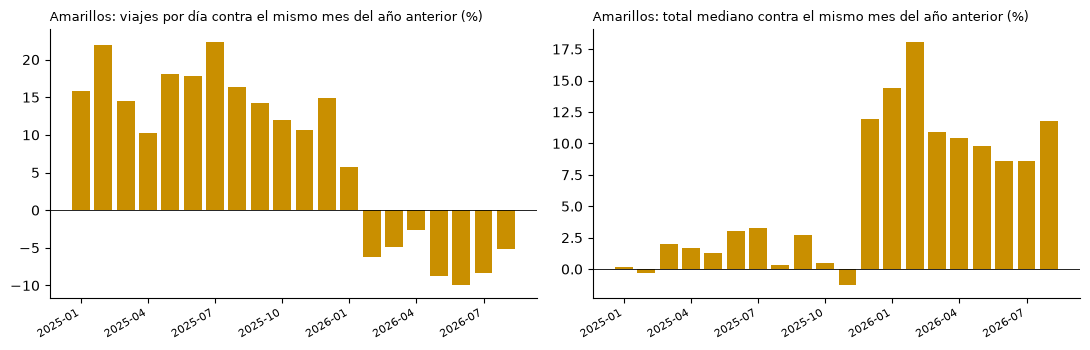

In [6]:
var = con.sql((SQL / "8_2_variacion_interanual.sql").read_text(encoding="utf-8")).df()
amarillos = var[(var.tipo == "yellow") & var.var_total_pct.notna()].copy()
amarillos["periodo"] = amarillos.anio.astype(str) + "-" + amarillos.mes.astype(str).str.zfill(2)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
ejes[0].bar(amarillos.periodo, amarillos.var_viajes_pct, color="#c98f00")
ejes[0].set_title("Amarillos: viajes por día contra el mismo mes del año anterior (%)", loc="left", fontsize=9)
ejes[1].bar(amarillos.periodo, amarillos.var_total_pct, color="#c98f00")
ejes[1].set_title("Amarillos: total mediano contra el mismo mes del año anterior (%)", loc="left", fontsize=9)
for eje in ejes:
    eje.axhline(0, color="black", linewidth=0.6)
    eje.set_xticks(range(0, len(amarillos), 3))
    eje.set_xticklabels(amarillos.periodo.iloc[::3], rotation=30, ha="right", fontsize=8)
    eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 8.6 El cargo de congestión mes a mes

Desde cuándo existe el cargo, a cuántos viajes se les cobra y de cuánto es.

In [7]:
correr('8_3_cargo_congestion')

-- 8.6 El cargo de congestion del centro de Manhattan, mes a mes desde que existe.
-- Objetivo: ver cuando aparece cbd_congestion_fee, que proporcion de viajes lo
-- paga y de cuanto es. En 2024 la columna no existe (nulo), asi que solo se
-- listan los meses con la columna presente. Un viaje cuenta como "con cargo" si
-- el valor es mayor a cero.
-- Fuente: vista viajes_limpios (sql/ejercicio_07/00_vistas_tablero.sql).
SELECT
    tipo,
    strftime(make_date(anio, mes, 1), '%Y-%m') AS mes,
    count(*) AS viajes,
    round(100.0 * count(*) FILTER (WHERE cbd_congestion_fee > 0) / count(*), 1) AS pct_con_cargo,
    round(avg(cbd_congestion_fee) FILTER (WHERE cbd_congestion_fee > 0), 2) AS cargo_promedio,
    round(max(cbd_congestion_fee), 2) AS cargo_maximo
FROM viajes_limpios
WHERE cbd_congestion_fee IS NOT NULL
GROUP BY tipo, anio, mes
ORDER BY tipo, mes;



,tipo,mes,viajes,pct_con_cargo,cargo_promedio,cargo_maximo
0,green,2025-01,43016,7.6,0.75,0.75
1,green,2025-02,41404,9.2,0.75,0.75
2,green,2025-03,47196,10.1,0.75,0.75
3,green,2025-04,47707,10.5,0.75,0.75
4,green,2025-05,51087,10.7,0.75,0.75
5,green,2025-06,46150,10.5,0.75,0.75
6,green,2025-07,45770,10.0,0.75,0.75
7,green,2025-08,43891,10.9,0.75,0.75
8,green,2025-09,46648,10.2,0.75,0.75
9,green,2025-10,47028,9.8,0.75,0.75


## 8.5 y 8.6 La tarifa flexible mes a mes

Para ubicar en qué momento crece la proporción de viajes de tarifa flexible.

In [8]:
correr('8_4_tarifa_flexible_mensual')

-- 8.5 y 8.6 Tarifa flexible (Flex Fare), mes a mes en los tres anios.
-- Objetivo: ubicar en que momento crece la proporcion de viajes de tarifa
-- flexible y si lo hace de golpe o de forma gradual. En amarillos viene como
-- payment_type 0 y en verdes como nulo, por eso se juntan con coalesce.
-- Fuente: vista viajes_anio (sql/ejercicio_07/00_vistas_tablero.sql).
SELECT
    tipo,
    strftime(make_date(anio, mes, 1), '%Y-%m') AS mes,
    count(*) AS viajes,
    round(100.0 * count(*) FILTER (WHERE coalesce(payment_type, 0) = 0) / count(*), 1) AS pct_tarifa_flexible
FROM viajes_anio
GROUP BY tipo, anio, mes
ORDER BY tipo, mes;



,tipo,mes,viajes,pct_tarifa_flexible
0,green,2024-01,56555,6.0
1,green,2024-02,53578,5.5
2,green,2024-03,57451,3.7
3,green,2024-04,56473,3.5
4,green,2024-05,61007,3.1
5,green,2024-06,54738,3.5
6,green,2024-07,51820,3.1
7,green,2024-08,51806,3.1
8,green,2024-09,54422,3.1
9,green,2024-10,56153,2.9


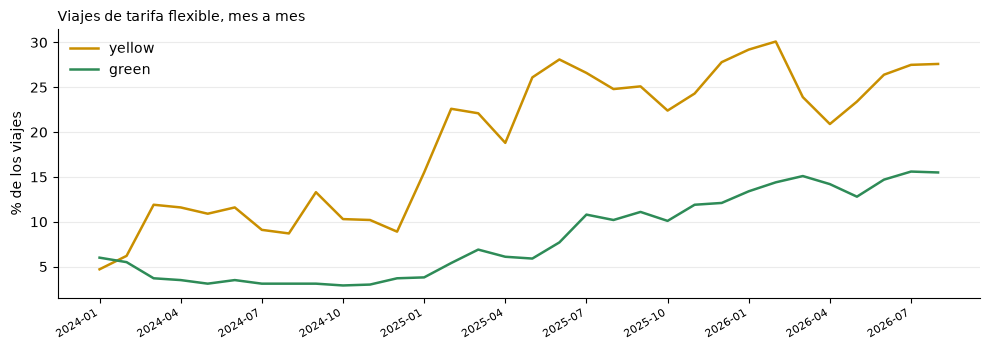

In [9]:
flex = con.sql((SQL / "8_4_tarifa_flexible_mensual.sql").read_text(encoding="utf-8")).df()
fig, eje = plt.subplots(figsize=(10, 3.6))
for tipo, color in [("yellow", "#c98f00"), ("green", "#2e8b57")]:
    d = flex[flex.tipo == tipo]
    eje.plot(d.mes, d.pct_tarifa_flexible, label=tipo, color=color, linewidth=1.8)
eje.set_xticks(range(0, 32, 3))
eje.set_xticklabels(sorted(flex.mes.unique())[::3], rotation=30, ha="right", fontsize=8)
eje.set_ylabel("% de los viajes")
eje.set_title("Viajes de tarifa flexible, mes a mes", loc="left", fontsize=10)
eje.spines[["top", "right"]].set_visible(False)
eje.grid(axis="y", alpha=0.25)
eje.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8.6 Peso de los aeropuertos

Proporción de viajes que salen de un aeropuerto y que pagan el recargo de aeropuerto.

In [10]:
correr('8_5_aeropuertos_por_anio')

-- 8.5 y 8.6 Peso de los aeropuertos en los viajes, mismos meses.
-- Objetivo: ver si la proporcion de viajes que salen de un aeropuerto (zonas 1
-- EWR, 132 JFK y 138 LaGuardia) y la que paga el recargo de aeropuerto
-- (solo existe en amarillos) cambian entre 2024, 2025 y 2026, con enero a
-- agosto de cada anio.
-- Fuente: vista viajes_limpios (sql/ejercicio_07/00_vistas_tablero.sql).
SELECT
    tipo,
    anio,
    count(*) AS viajes,
    round(100.0 * count(*) FILTER (WHERE PULocationID IN (1, 132, 138)) / count(*), 2) AS pct_salen_de_aeropuerto,
    round(100.0 * count(*) FILTER (WHERE Airport_fee > 0)
          / nullif(count(*) FILTER (WHERE Airport_fee IS NOT NULL), 0), 2) AS pct_con_recargo_aeropuerto
FROM viajes_limpios
WHERE mes <= 8
GROUP BY tipo, anio
ORDER BY tipo, anio;



,tipo,anio,viajes,pct_salen_de_aeropuerto,pct_con_recargo_aeropuerto
0,green,2024,412714,0.05,NaN
1,green,2025,369581,0.04,NaN
2,green,2026,319257,0.03,NaN
3,yellow,2024,25492918,7.92,8.89
4,yellow,2025,29704030,6.75,8.78
5,yellow,2026,28146188,6.48,8.69


## Cierre

Los patrones que encontramos, las respuestas a 8.5 y 8.6 y la discusión de qué cambia y qué no están en `docs/ejercicio_08.md`.